# Modelo de Previsão de Inadimplência de Cartão de Crédito


**Origem da Base de Dados (Item 1):**  
Repositório oficial **UCI Machine Learning Repository** — *Default of Credit Card Clients* (ID `350` no UCI, espelhado sob o ID `42477` no OpenML).  
- URL Oficial UCI: `https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients`  
- Instâncias: 30.000 clientes | Atributos: 23 variáveis explicativas + 1 variável alvo (`default payment next month`).

In [ ]:
# 1. IMPORTAÇÃO E CARREGAMENTO DIRETO DO UCI

!pip install -q ucimlrepo

import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    ConfusionMatrixDisplay
)
import xgboost as xgb
from ucimlrepo import fetch_ucirepo

# Mapeamento oficial das colunas do dataset UCI (ID 350)
colunas_uci = {
    'X1': 'LIMIT_BAL', 'X2': 'SEX', 'X3': 'EDUCATION', 'X4': 'MARRIAGE', 'X5': 'AGE',
    'X6': 'PAY_0', 'X7': 'PAY_2', 'X8': 'PAY_3', 'X9': 'PAY_4', 'X10': 'PAY_5', 'X11': 'PAY_6',
    'X12': 'BILL_AMT1', 'X13': 'BILL_AMT2', 'X14': 'BILL_AMT3', 'X15': 'BILL_AMT4', 'X16': 'BILL_AMT5', 'X17': 'BILL_AMT6',
    'X18': 'PAY_AMT1', 'X19': 'PAY_AMT2', 'X20': 'PAY_AMT3', 'X21': 'PAY_AMT4', 'X22': 'PAY_AMT5', 'X23': 'PAY_AMT6',
    'Y': 'default.payment.next.month'
}

# Baixa a base diretamente do UCI Machine Learning Repository (ID 350)
dataset = fetch_ucirepo(id=350)
df = pd.concat([dataset.data.features, dataset.data.targets], axis=1)
df = df.rename(columns=colunas_uci)
df = df.apply(pd.to_numeric)

print("Base carregada de: UCI Machine Learning Repository (pacote ucimlrepo, ID=350)")
print(f"Dimensões iniciais: {df.shape[0]} linhas x {df.shape[1]} colunas")
display(df.head())

Base carregada de: UCI Machine Learning Repository (pacote ucimlrepo, ID=350)
Dimensões iniciais: 30000 linhas x 24 colunas


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [ ]:
# 2. ESTATÍSTICAS DESCRITIVAS GERAIS (ITEM 3 — ANTES DAS TRANSFORMAÇÕES)

print("--- INFORMAÇÕES GERAIS DA BASE (df.info) ---")
df.info()

print("\n--- CONTAGEM DE VALORES NULOS POR COLUNA ---")
print(df.isnull().sum())

print("\n--- ESTATÍSTICAS DESCRITIVAS NUMÉRICAS (df.describe) ---")
display(df.describe().T)

print("\n--- DISTRIBUIÇÃO DAS VARIÁVEIS CATEGÓRICAS (ANTES DA LIMPEZA) ---")
for col in ['SEX', 'EDUCATION', 'MARRIAGE']:
    print(f"\nFrequência de {col}:")
    freq = pd.DataFrame({
        'Contagem': df[col].value_counts().sort_index(),
        'Percentual (%)': (df[col].value_counts(normalize=True).sort_index() * 100).round(2)
    })
    display(freq)

print("\n--- CONCEITOS (CLASSES) A SEREM APRENDIDOS ---")
print(f"Exemplares: {df.shape[0]} | Características: {df.shape[1] - 1}")
distribuicao = df['default.payment.next.month'].value_counts().sort_index()
for classe, qtd in distribuicao.items():
    rotulo = "Pagou (0)" if classe == 0 else "Inadimplente (1)"
    print(f"  {rotulo}: {qtd} exemplares ({qtd / len(df):.2%})")

--- INFORMAÇÕES GERAIS DA BASE (df.info) ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 24 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   LIMIT_BAL                   30000 non-null  int64
 1   SEX                         30000 non-null  int64
 2   EDUCATION                   30000 non-null  int64
 3   MARRIAGE                    30000 non-null  int64
 4   AGE                         30000 non-null  int64
 5   PAY_0                       30000 non-null  int64
 6   PAY_2                       30000 non-null  int64
 7   PAY_3                       30000 non-null  int64
 8   PAY_4                       30000 non-null  int64
 9   PAY_5                       30000 non-null  int64
 10  PAY_6                       30000 non-null  int64
 11  BILL_AMT1                   30000 non-null  int64
 12  BILL_AMT2                   30000 non-null  int64
 13  BILL_AMT3       

,count,mean,std,min,25%,50%,75%,max
LIMIT_BAL,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.00,1000000.0
SEX,30000.0,1.603733,0.489129,1.0,1.00,2.0,2.00,2.0
EDUCATION,30000.0,1.853133,0.790349,0.0,1.00,2.0,2.00,6.0
MARRIAGE,30000.0,1.551867,0.521970,0.0,1.00,2.0,2.00,3.0
AGE,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.00,79.0
PAY_0,30000.0,-0.016700,1.123802,-2.0,-1.00,0.0,0.00,8.0
PAY_2,30000.0,-0.133767,1.197186,-2.0,-1.00,0.0,0.00,8.0
PAY_3,30000.0,-0.166200,1.196868,-2.0,-1.00,0.0,0.00,8.0
PAY_4,30000.0,-0.220667,1.169139,-2.0,-1.00,0.0,0.00,8.0
PAY_5,30000.0,-0.266200,1.133187,-2.0,-1.00,0.0,0.00,8.0



--- DISTRIBUIÇÃO DAS VARIÁVEIS CATEGÓRICAS (ANTES DA LIMPEZA) ---

Frequência de SEX:


,Contagem,Percentual (%)
SEX,,
1,11888,39.63
2,18112,60.37



Frequência de EDUCATION:


,Contagem,Percentual (%)
EDUCATION,,
0,14,0.05
1,10585,35.28
2,14030,46.77
3,4917,16.39
4,123,0.41
5,280,0.93
6,51,0.17



Frequência de MARRIAGE:


,Contagem,Percentual (%)
MARRIAGE,,
0,54,0.18
1,13659,45.53
2,15964,53.21
3,323,1.08



--- CONCEITOS (CLASSES) A SEREM APRENDIDOS ---
Exemplares: 30000 | Características: 23
  Pagou (0): 23364 exemplares (77.88%)
  Inadimplente (1): 6636 exemplares (22.12%)


In [ ]:
# 3. TRANSFORMAÇÃO EM LINHAS (ITEM 5 — REMOÇÃO REAL DE DUPLICATAS E INVÁLIDOS)

linhas_antes = len(df)
print(f"Total de linhas ANTES das transformações: {linhas_antes}")

# 3.1 Remove valores nulos e registros duplicados
df = df.dropna()
duplicadas = df.duplicated().sum()
df = df.drop_duplicates()
print(f"Registros duplicados removidos: {duplicadas}")

# 3.2 Filtra categorias não documentadas/inválidas segundo o dicionário do UCI:
# EDUCATION válidos: 1 (pós-graduação), 2 (universidade), 3 (ensino médio), 4 (outros) -> remove 0, 5, 6
# MARRIAGE válidos:  1 (casado), 2 (solteiro), 3 (outros) -> remove 0
invalidos_edu = (~df['EDUCATION'].isin([1, 2, 3, 4])).sum()
invalidos_mar = (~df['MARRIAGE'].isin([1, 2, 3])).sum()

df = df[df['EDUCATION'].isin([1, 2, 3, 4]) & df['MARRIAGE'].isin([1, 2, 3])].copy()

linhas_depois = len(df)
print(f"Registros com EDUCATION inválido (0, 5, 6): {invalidos_edu}")
print(f"Registros com MARRIAGE inválido (0):        {invalidos_mar}")
print(f"Total de linhas DEPOIS das transformações: {linhas_depois} (removidas {linhas_antes - linhas_depois} linhas no total)")

Total de linhas ANTES das transformações: 30000
Registros duplicados removidos: 35
Registros com EDUCATION inválido (0, 5, 6): 345
Registros com MARRIAGE inválido (0):        54
Total de linhas DEPOIS das transformações: 29566 (removidas 434 linhas no total)


In [ ]:
# 4. TRANSFORMAÇÃO EM COLUNAS (ITEM 4)

print(f"Total de colunas ANTES: {df.shape[1]}")

# 4.1 Verificação e remoção da coluna ID (não agrega poder preditivo)
if 'ID' in df.columns:
    df = df.drop(columns=['ID'])
    print("Coluna 'ID' encontrada e removida.")
else:
    print("Nota: A coluna 'ID' já não está presente nesta extração direta dos atributos do UCI.")

# 4.2 Criação de nova coluna (Feature Engineering): Índice de Utilização do Limite no 1º mês
df['UTILIZACAO_LIMITE_M1'] = (df['BILL_AMT1'] / df['LIMIT_BAL']).round(4)

# 4.3 One-Hot Encoding explícito nas variáveis categóricas nominais (SEX, EDUCATION, MARRIAGE)
df = pd.get_dummies(df, columns=['SEX', 'EDUCATION', 'MARRIAGE'], drop_first=True, dtype=int)

# 4.4 Normalização (StandardScaler) das colunas monetárias (BILL_AMT1..6 e PAY_AMT1..6)
cols_monetarias = [f'BILL_AMT{i}' for i in range(1, 7)] + [f'PAY_AMT{i}' for i in range(1, 7)]
scaler = StandardScaler()
df[cols_monetarias] = scaler.fit_transform(df[cols_monetarias])

print(f"Total de colunas DEPOIS: {df.shape[1]}")
print("Novas colunas criadas via One-Hot e Engenharia de Atributos:")
print([c for c in df.columns if c.startswith(('SEX_', 'EDUCATION_', 'MARRIAGE_', 'UTILIZACAO'))])
display(df.head())

Total de colunas ANTES: 24
Nota: A coluna 'ID' já não está presente nesta extração direta dos atributos do UCI.
Total de colunas DEPOIS: 28
Novas colunas criadas via One-Hot e Engenharia de Atributos:
['UTILIZACAO_LIMITE_M1', 'SEX_2', 'EDUCATION_2', 'EDUCATION_3', 'EDUCATION_4', 'MARRIAGE_2', 'MARRIAGE_3']


,LIMIT_BAL,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,...,PAY_AMT5,PAY_AMT6,default.payment.next.month,UTILIZACAO_LIMITE_M1,SEX_2,EDUCATION_2,EDUCATION_3,EDUCATION_4,MARRIAGE_2,MARRIAGE_3
0,20000,24,2,2,-1,-1,-2,-2,-0.641826,-0.646953,...,-0.314751,-0.293626,1,0.1956,1,1,0,0,0,0
1,120000,26,-1,2,0,0,0,2,-0.658599,-0.666362,...,-0.314751,-0.180418,1,0.0223,1,1,0,0,1,0
2,90000,34,0,0,0,0,0,0,-0.296745,-0.492960,...,-0.249186,-0.010605,0,0.3249,1,1,0,0,1,0
3,50000,37,0,0,0,0,0,0,-0.054878,-0.010811,...,-0.244662,-0.237022,0,0.9398,1,1,0,0,0,0
4,50000,57,-1,0,-1,0,0,0,-0.577731,-0.610756,...,-0.269576,-0.255192,0,0.1723,0,1,0,0,0,0


In [ ]:

# 5. DIVISÃO EM TREINO (80%), VALIDAÇÃO (10%) E TESTE (10%)

target_col = 'default.payment.next.month'
X = df.drop(columns=[target_col])
y = df[target_col].astype(int)

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

print(f"Treino:    {X_train.shape[0]} amostras")
print(f"Validação: {X_val.shape[0]} amostras")
print(f"Teste:     {X_test.shape[0]} amostras")

Treino:    23652 amostras
Validação: 2957 amostras
Teste:     2957 amostras


In [ ]:
# 6. TREINAMENTO DO MODELO XGBOOST

modelo_xgb = xgb.XGBClassifier(
    objective="binary:logistic",
    eval_metric="auc",
    n_estimators=100,
    max_depth=5,
    learning_rate=0.2,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
)

modelo_xgb.fit(
    X_train,
    y_train,
    eval_set=[(X_train, y_train), (X_val, y_val)],
    verbose=False
)

print("Treinamento concluído com sucesso!")

# 6.1 SEPARA 1 EXEMPLAR INÉDITO DO CONJUNTO DE TESTE (ITEM 9)
# Esta linha NÃO será usada na validação nem no teste do modelo.
posicao = 1  # troque este número para escolher outra linha do conjunto de teste

exemplar_X = X_test.iloc[[posicao]].copy()   # apenas as características
exemplar_y = int(y_test.iloc[posicao])       # conceito real (guardado só para conferir depois)

X_test = X_test.drop(index=exemplar_X.index)
y_test = y_test.drop(index=exemplar_X.index)

print(f"Exemplar inédito separado (índice {exemplar_X.index[0]}).")
print(f"Conjunto de teste restante: {X_test.shape[0]} amostras")

Treinamento concluído com sucesso!
Exemplar inédito separado (índice 18797).
Conjunto de teste restante: 2956 amostras


AUC-ROC no Teste:  0.7692
Acurácia no Teste: 0.8068

Relatório de Classificação:
                  precision    recall  f1-score   support

       Pagou (0)       0.84      0.93      0.88      2296
Inadimplente (1)       0.61      0.37      0.46       660

        accuracy                           0.81      2956
       macro avg       0.72      0.65      0.67      2956
    weighted avg       0.79      0.81      0.79      2956



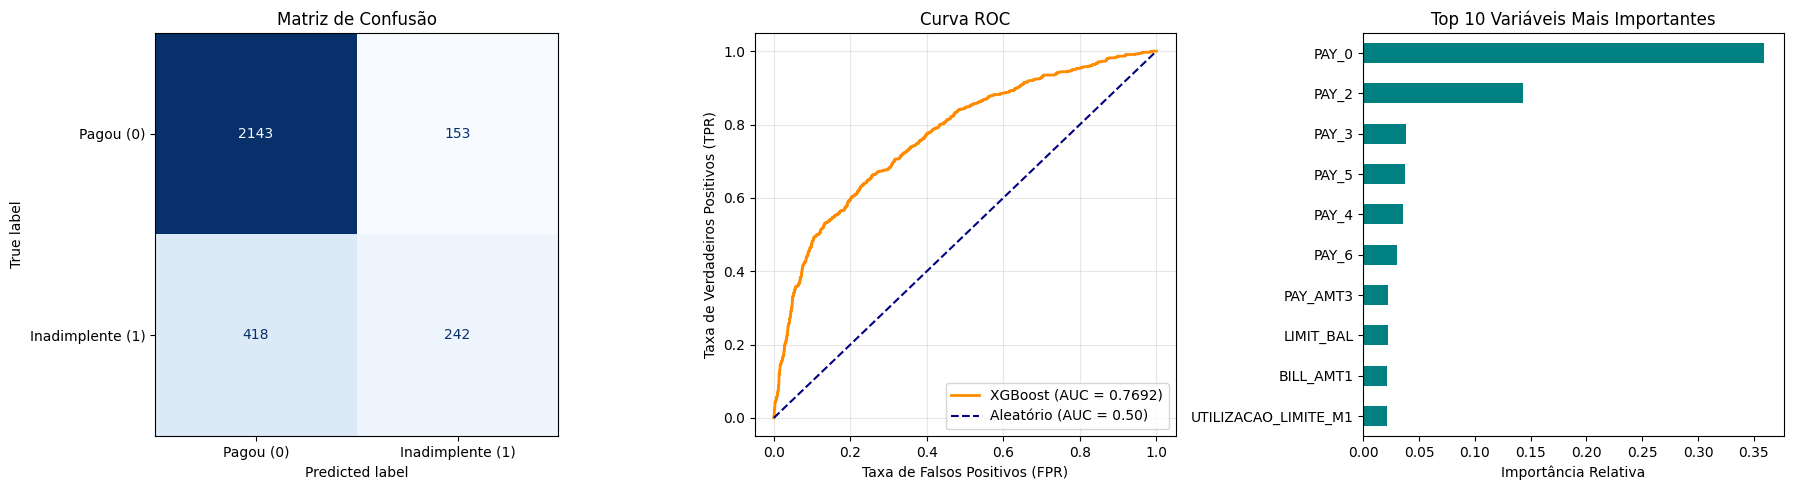

In [ ]:
# 7. MÉTRICAS E GRÁFICOS DE AVALIAÇÃO

y_prob = modelo_xgb.predict_proba(X_test)[:, 1]
y_pred = (y_prob >= 0.5).astype(int)

auc = roc_auc_score(y_test, y_prob)
acc = accuracy_score(y_test, y_pred)

print(f"AUC-ROC no Teste:  {auc:.4f}")
print(f"Acurácia no Teste: {acc:.4f}\n")
print("Relatório de Classificação:")
print(classification_report(y_test, y_pred, target_names=["Pagou (0)", "Inadimplente (1)"]))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Matriz de Confusão
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Pagou (0)", "Inadimplente (1)"])
disp.plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Matriz de Confusão")

# Curva ROC
fpr, tpr, _ = roc_curve(y_test, y_prob)
axes[1].plot(fpr, tpr, color="darkorange", lw=2, label=f"XGBoost (AUC = {auc:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=1.5, linestyle="--", label="Aleatório (AUC = 0.50)")
axes[1].set_xlabel("Taxa de Falsos Positivos (FPR)")
axes[1].set_ylabel("Taxa de Verdadeiros Positivos (TPR)")
axes[1].set_title("Curva ROC")
axes[1].legend(loc="lower right")
axes[1].grid(alpha=0.3)

# Top 10 Variáveis Mais Importantes
importancias = pd.Series(modelo_xgb.feature_importances_, index=X.columns)
importancias.nlargest(10).sort_values().plot(kind="barh", ax=axes[2], color="teal")
axes[2].set_title("Top 10 Variáveis Mais Importantes")
axes[2].set_xlabel("Importância Relativa")

plt.tight_layout()
plt.show()

In [ ]:
# 8. PERSISTÊNCIA E PREDIÇÃO DO MODELO IMPLANTADO (ITEM 9)

# 8.1 Salva o modelo treinado, o scaler e a ordem exata das colunas
artefato_modelo = {
    'modelo': modelo_xgb,
    'colunas': list(X_train.columns)
}
arquivo_modelo = 'modelo_inadimplencia_xgb.joblib'
joblib.dump(artefato_modelo, arquivo_modelo)
print(f"Modelo salvo com sucesso em: '{arquivo_modelo}'")

# 8.2 Carrega o modelo salvo do disco (simulando ambiente de produção/implantação)
modelo_carregado = joblib.load(arquivo_modelo)
modelo_implantado = modelo_carregado['modelo']
colunas_modelo = modelo_carregado['colunas']

# 8.3 Apresenta ao modelo SOMENTE as características do exemplar inédito (sem o rótulo)
exemplar_entrada = exemplar_X.reindex(columns=colunas_modelo)
print("\nCaracterísticas apresentadas ao modelo (já transformadas):")
display(exemplar_entrada.T)

# 8.4 Predição online de um único exemplar
probabilidade = modelo_implantado.predict_proba(exemplar_entrada)[0, 1]
classe_prevista = int(probabilidade >= 0.5)

nomes = {0: "Pagou (0)", 1: "Inadimplente (1)"}
print("\n--- RESULTADO DA PREDIÇÃO ---")
print(f"Probabilidade de inadimplência: {probabilidade:.2%}")
print(f"Conceito previsto pelo modelo:  {nomes[classe_prevista]}")
print(f"Conceito real do exemplar:      {nomes[exemplar_y]}")
print("Resultado:", "ACERTOU" if classe_prevista == exemplar_y else "ERROU")

Modelo salvo com sucesso em: 'modelo_inadimplencia_xgb.joblib'

Características apresentadas ao modelo (já transformadas):


,18797
LIMIT_BAL,50000.000000
AGE,29.000000
PAY_0,0.000000
PAY_2,0.000000
PAY_3,0.000000
PAY_4,0.000000
PAY_5,0.000000
PAY_6,0.000000
BILL_AMT1,-0.063258
BILL_AMT2,-0.021439



--- RESULTADO DA PREDIÇÃO ---
Probabilidade de inadimplência: 23.25%
Conceito previsto pelo modelo:  Pagou (0)
Conceito real do exemplar:      Pagou (0)
Resultado: ACERTOU
